# Classification des essences forestières

## Objectif

À partir de caractéristiques du terrain, prédire l'une des sept classes de couverture forestière pour une parcelle de 30 × 30 m. Nous comparerons une baseline, un SVM, un K plus proches voisins et une forêt aléatoire.

Le jeu de données **Covertype** est public et téléchargeable directement avec scikit-learn ; aucune authentification Google Drive n'est requise. Source : [UCI Covertype](https://archive.ics.uci.edu/dataset/31/covertype) et [chargement scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_covtype.html).

| Étiquette | Essence / couverture |
|---:|---|
| 0 | Spruce / fir |
| 1 | Lodgepole pine |
| 2 | Ponderosa pine |
| 3 | Cottonwood / willow |
| 4 | Aspen |
| 5 | Douglas-fir |
| 6 | Krummholz |

Le fichier original contient 581 012 parcelles et 54 variables. Pour garder ce TP accessible, nous utilisons un échantillon stratifié de 10 000 parcelles et les 14 caractéristiques décrites ci-dessous : dix mesures numériques du terrain et quatre indicateurs de zone de nature sauvage.

**Parcours :** explorer les classes et les variables, définir OA et mIoU, séparer entraînement/test, comparer les modèles par validation croisée, régler le SVM, puis évaluer le modèle choisi sur le test final.

In [2]:
%pip install scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [16]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_covtype
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

np.random.seed(42)
class_names = [
    "Spruce/fir",
    "Lodgepole pine",
    "Ponderosa pine",
    "Cottonwood/willow",
    "Aspen",
    "Douglas-fir",
    "Krummholz",
]
print("Imports prêts ; les données seront téléchargées dans la cellule suivante.")

Imports prêts ; les données seront téléchargées dans la cellule suivante.


In [4]:
# Covertype est un jeu public fourni par scikit-learn.
covertype = fetch_covtype(as_frame=False, download_if_missing=True)
labels_completes = covertype.target.astype(np.int8) - 1
indices = np.arange(labels_completes.shape[0])

# Sous-échantillon stratifié pour garder toutes les classes et accélérer le TP.
indices_echantillon, _ = train_test_split(
    indices,
    train_size=10_000,
    random_state=42,
    stratify=labels_completes,
)

# Les 14 premières colonnes sont les dix mesures numériques et quatre zones.
feature_names = covertype.feature_names[:14]
data = covertype.data[indices_echantillon, :14].astype(np.float32)
label = labels_completes[indices_echantillon]

print(f"Jeu public complet : {covertype.data.shape[0]:,} parcelles, {covertype.data.shape[1]} variables")
print(f"Échantillon du TP : {data.shape[0]:,} parcelles, {data.shape[1]} variables")
print(f"Classes : {len(class_names)}")

Jeu public complet : 581,012 parcelles, 54 variables
Échantillon du TP : 10,000 parcelles, 14 variables
Classes : 7


## 2. Explorer les classes et les variables

La classe cible prend les valeurs de 0 à 6. Commençons par compter les exemples de chaque espèce : si certaines classes sont rares, l'accuracy peut être élevée tout en masquant de mauvaises prédictions sur ces classes.

Spruce/fir           :  3646 parcelles (36.5%)
Lodgepole pine       :  4876 parcelles (48.8%)
Ponderosa pine       :   615 parcelles (6.2%)
Cottonwood/willow    :    47 parcelles (0.5%)
Aspen                :   164 parcelles (1.6%)
Douglas-fir          :   299 parcelles (3.0%)
Krummholz            :   353 parcelles (3.5%)


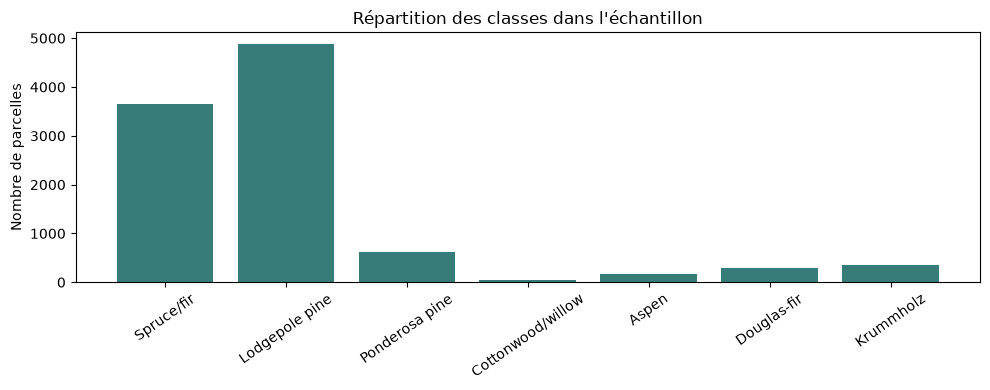

In [5]:
effectifs_classes = np.bincount(label, minlength=len(class_names))
proportions_classes = effectifs_classes / effectifs_classes.sum()

for nom, effectif, proportion in zip(
    class_names, effectifs_classes, proportions_classes
):
    print(f"{nom:20s} : {effectif:5d} parcelles ({proportion:.1%})")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(class_names, effectifs_classes, color="#377c78")
ax.set_ylabel("Nombre de parcelles")
ax.set_title("Répartition des classes dans l'échantillon")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()

### Interpréter la répartition

La classe `Lodgepole pine` représente près de la moitié de l'échantillon, tandis que `Cottonwood/willow` en représente environ 0,5 %. Le jeu est donc fortement déséquilibré. Un modèle qui favorise les classes fréquentes peut avoir une bonne accuracy tout en reconnaissant mal les espèces rares ; nous suivrons aussi le mIoU et les scores par classe.

## 3. Comprendre les caractéristiques

Nous utilisons les dix mesures numériques et les quatre indicateurs de zone du jeu Covertype. L'original contient aussi 40 indicateurs de type de sol, volontairement laissés de côté pour garder ce TP centré sur les mesures de terrain.

| Caractéristique | Signification |
|---|---|
| `Elevation` | Altitude |
| `Aspect`, `Slope` | Orientation et pente du terrain |
| `Horizontal_Distance_To_Hydrology` | Distance horizontale à l'eau |
| `Vertical_Distance_To_Hydrology` | Écart vertical par rapport à l'eau |
| `Horizontal_Distance_To_Roadways` | Distance aux routes |
| `Hillshade_9am`, `Hillshade_Noon`, `Hillshade_3pm` | Ombrage estimé à trois moments de la journée |
| `Horizontal_Distance_To_Fire_Points` | Distance aux points d'incendie connus |
| `Wilderness_Area_0` à `_3` | Indicateurs binaires des quatre zones |

Les dix premières variables sont des mesures numériques ; les quatre dernières sont binaires. Nous standardiserons les mesures continues pour les modèles sensibles aux échelles, mais garderons les indicateurs binaires tels quels.

In [6]:
print(f"Dimensions de data : {data.shape} (parcelles, caractéristiques)")

for index, nom in enumerate(feature_names):
    valeurs = data[:, index]
    print(
        f"{index:2d}. {nom:45s} "
        f"min={valeurs.min():8.1f} max={valeurs.max():8.1f}"
    )

print("\nValeurs uniques des indicateurs de zone :")
for nom, valeurs in zip(feature_names[10:], data[:, 10:].T):
    print(f"{nom}: {np.unique(valeurs)}")

Dimensions de data : (10000, 14) (parcelles, caractéristiques)
 0. Elevation                                     min=  1876.0 max=  3856.0
 1. Aspect                                        min=     0.0 max=   360.0
 2. Slope                                         min=     0.0 max=    51.0
 3. Horizontal_Distance_To_Hydrology              min=     0.0 max=  1343.0
 4. Vertical_Distance_To_Hydrology                min=  -152.0 max=   544.0
 5. Horizontal_Distance_To_Roadways               min=     0.0 max=  7039.0
 6. Hillshade_9am                                 min=     0.0 max=   254.0
 7. Hillshade_Noon                                min=   100.0 max=   254.0
 8. Hillshade_3pm                                 min=     0.0 max=   248.0
 9. Horizontal_Distance_To_Fire_Points            min=     0.0 max=  6930.0
10. Wilderness_Area_0                             min=     0.0 max=     1.0
11. Wilderness_Area_1                             min=     0.0 max=     1.0
12. Wilderness_Area_2    

In [ ]:
indices_numeriques = list(range(10))
indices_binaires = list(range(10, 14))

for index in indices_binaires:
    assert set(np.unique(data[:, index])).issubset({0.0, 1.0})

print(f"Mesures continues à standardiser : {len(indices_numeriques)}")
print(f"Indicateurs binaires à conserver : {len(indices_binaires)}")
print("Aucune transformation n'est ajustée ici : on séparera d'abord les données.")

[ 1.1086726e-05 -1.9431114e-09 -1.0836124e-08  5.7029723e-08
 -2.2634865e-08  2.3528726e-06 -2.5376677e-08 -2.0028352e-07
 -4.8320366e-08  5.6904702e-07]


## 4. Mesurer la qualité des prédictions

Une matrice de confusion compare la classe réelle (ligne) à la classe prédite (colonne). Les valeurs sur la diagonale sont les bonnes classifications ; les autres indiquent les confusions entre espèces.

**Overall Accuracy (OA)** est la proportion totale de parcelles correctement classées. Elle est facile à lire, mais peut être dominée par les classes majoritaires.

$$
OA = \frac{\text{nombre de prédictions correctes}}{\text{nombre total de parcelles}}
$$

**Intersection over Union (IoU)** mesure la qualité pour une classe précise. Pour la classe $i$, on divise ses vrais positifs par tous les pixels réels ou prédits comme $i$ :

$$
IoU_i = \frac{TP_i}{TP_i + FP_i + FN_i}
$$

Le **mIoU** est la moyenne des IoU des classes présentes. Chaque classe pèse ainsi autant, ce qui aide à voir les mauvaises performances sur les espèces rares.

In [7]:
from sklearn.metrics import confusion_matrix


def calculer_metriques(y_true, y_pred, n_classes):
    matrice = confusion_matrix(
        y_true, y_pred, labels=np.arange(n_classes)
    )
    vrais_positifs = np.diag(matrice)
    denominateur = matrice.sum(axis=1) + matrice.sum(axis=0) - vrais_positifs
    iou_par_classe = np.divide(
        vrais_positifs,
        denominateur,
        out=np.full(n_classes, np.nan, dtype=float),
        where=denominateur != 0,
    )
    accuracy = vrais_positifs.sum() / matrice.sum()
    miou = np.nanmean(iou_par_classe)
    return accuracy, miou, iou_par_classe, matrice


def afficher_metriques(y_true, y_pred, noms_classes):
    accuracy, miou, iou_par_classe, matrice = calculer_metriques(
        y_true, y_pred, len(noms_classes)
    )
    print(f"OA : {accuracy:.1%}")
    print(f"mIoU : {miou:.1%}")
    print("\nIoU par classe :")
    for nom, iou in zip(noms_classes, iou_par_classe):
        valeur = "non défini" if np.isnan(iou) else f"{iou:.1%}"
        print(f"- {nom} : {valeur}")
    print("\nMatrice de confusion (lignes = réel, colonnes = prédit) :")
    print(matrice)


# Petit exemple artificiel : la classe 1 est souvent confondue avec la classe 0.
y_exemple = np.array([0, 1, 1, 0, 2, 2])
y_pred_exemple = np.array([0, 0, 1, 0, 2, 1])
afficher_metriques(y_exemple, y_pred_exemple, ["Classe A", "Classe B", "Classe C"])

OA : 66.7%
mIoU : 50.0%

IoU par classe :
- Classe A : 66.7%
- Classe B : 33.3%
- Classe C : 50.0%

Matrice de confusion (lignes = réel, colonnes = prédit) :
[[2 0 0]
 [1 1 0]
 [0 1 1]]


## 5. Séparer entraînement et test

Le jeu d'entraînement sert à ajuster les modèles et à choisir les paramètres par validation croisée. Le jeu de test reste de côté jusqu'à l'évaluation finale. `stratify=label` conserve une répartition comparable des espèces dans les deux lots.

Nous ne standardisons pas `data` avant cette étape : les transformations seront apprises dans les pipelines à partir des seuls plis d'entraînement.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    data,
    label,
    test_size=0.2,
    random_state=42,
    stratify=label,
)

print(f"Train : {len(y_train):,} parcelles")
print(f"Test final : {len(y_test):,} parcelles")
print("Les deux ensembles conservent les proportions des sept classes.")

Train : 8,000 parcelles
Test final : 2,000 parcelles
Les deux ensembles conservent les proportions des sept classes.


## 6. Comparer plusieurs classificateurs

On évaluera une baseline majoritaire, un SVM, un KNN et une forêt aléatoire sur les mêmes plis stratifiés du jeu d'entraînement. Les modèles sensibles aux échelles reçoivent un prétraitement intégré à leur pipeline ; les quatre indicateurs binaires restent inchangés.

Nous comparerons l'OA et le mIoU. La moyenne sur les plis aide à comparer les modèles sans consulter le test final.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.metrics import make_scorer
from sklearn.model_selection import cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

indices_numeriques = list(range(10))
indices_binaires = list(range(10, 14))
preprocesseur_distance = ColumnTransformer(
    transformers=[
        ("mesures", StandardScaler(), indices_numeriques),
        ("zones", "passthrough", indices_binaires),
    ],
    verbose_feature_names_out=False,
)


def score_miou(y_true, y_pred):
    return calculer_metriques(y_true, y_pred, len(class_names))[1]


score_miou_cv = make_scorer(score_miou)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

models = {
    "Baseline majoritaire": DummyClassifier(strategy="most_frequent"),
    "SVM linéaire": Pipeline(
        steps=[
            ("preparation", preprocesseur_distance),
            ("classifieur", SVC(kernel="linear", C=10, class_weight="balanced")),
        ]
    ),
    "SVM RBF": Pipeline(
        steps=[
            ("preparation", preprocesseur_distance),
            ("classifieur", SVC(kernel="rbf", C=10, class_weight="balanced")),
        ]
    ),
    "K plus proches voisins": Pipeline(
        steps=[
            ("preparation", preprocesseur_distance),
            ("classifieur", KNeighborsClassifier(n_neighbors=10, weights="distance")),
        ]
    ),
    "Forêt aléatoire": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
    ),
}

resultats_cv = []
for nom, estimateur in models.items():
    scores = cross_validate(
        estimateur,
        X_train,
        y_train,
        cv=cv,
        scoring={"OA": "accuracy", "mIoU": score_miou_cv},
        return_train_score=False,
    )
    resultats_cv.append(
        {
            "Modèle": nom,
            "OA moyenne": scores["test_OA"].mean(),
            "OA écart-type": scores["test_OA"].std(),
            "mIoU moyenne": scores["test_mIoU"].mean(),
            "mIoU écart-type": scores["test_mIoU"].std(),
        }
    )

tableau_comparaison = pd.DataFrame(resultats_cv).sort_values(
    "mIoU moyenne", ascending=False
).reset_index(drop=True)
display(tableau_comparaison.round(3))

,Modèle,OA moyenne,OA écart-type,mIoU moyenne,mIoU écart-type
0,Forêt aléatoire,0.769,0.004,0.423,0.022
1,SVM RBF,0.685,0.006,0.417,0.017
2,K plus proches voisins,0.722,0.003,0.355,0.024
3,SVM linéaire,0.561,0.008,0.323,0.005
4,Baseline majoritaire,0.488,0.000,0.070,0.000


### Lire la comparaison

La **forêt aléatoire** arrive en tête sur cette configuration : OA moyenne `0,769`, mIoU `0,423`. Le **SVM RBF** obtient une OA plus faible (`0,685`), mais un mIoU proche (`0,417`). Il reconnaît donc mieux les espèces rares que ne le laisserait penser la seule OA. Le **KNN** a une OA de `0,722`, mais son mIoU plus faible (`0,355`) indique des performances plus inégales entre espèces. Le **SVM linéaire** est moins performant ici ; le noyau RBF peut représenter des frontières non linéaires.

La baseline prédit toujours l'espèce majoritaire : son OA est déjà de `0,488`, mais son mIoU n'est que de `0,070`. Cela illustre le déséquilibre des classes. L'écart-type décrit la variation entre les trois plis ; ce n'est pas un intervalle de confiance. Les résultats restent préliminaires : nous allons régler les paramètres par validation croisée, puis utiliser le test final une seule fois.

## 7. Régler les hyperparamètres par validation croisée

`C` contrôle la pénalisation des erreurs du SVM ; le noyau linéaire crée une frontière plane, tandis que le noyau RBF peut modéliser des frontières plus complexes. `GridSearchCV` teste une petite grille de valeurs et sélectionne celle qui maximise le mIoU moyen en validation croisée.

La recherche s'effectue uniquement sur `X_train`. Les scores de CV servent à choisir le modèle et ses paramètres ; le test final reste intact jusqu'à la section suivante.

In [12]:
pipeline_svm = Pipeline(
    steps=[
        ("preparation", preprocesseur_distance),
        ("classifieur", SVC(class_weight="balanced")),
    ]
)

parametres_svm = [
    {
        "classifieur": [SVC(kernel="linear", class_weight="balanced")],
        "classifieur__C": [1, 10, 100],
    },
    {
        "classifieur": [SVC(kernel="rbf", class_weight="balanced")],
        "classifieur__C": [1, 10],
        "classifieur__gamma": ["scale", 0.01],
    },
]

recherche_svm = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=parametres_svm,
    scoring=score_miou_cv,
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
)
debut_recherche = time.perf_counter()
recherche_svm.fit(X_train, y_train)
duree_recherche = time.perf_counter() - debut_recherche

resultats_svm = []
for rang, moyenne, ecart_type, parametres in zip(
    recherche_svm.cv_results_["rank_test_score"],
    recherche_svm.cv_results_["mean_test_score"],
    recherche_svm.cv_results_["std_test_score"],
    recherche_svm.cv_results_["params"],
):
    classifieur = parametres["classifieur"]
    resultats_svm.append(
        {
            "Rang": rang,
            "Noyau": classifieur.kernel,
            "Paramètres": {cle: valeur for cle, valeur in parametres.items() if cle != "classifieur"},
            "mIoU moyenne": moyenne,
            "mIoU écart-type": ecart_type,
        }
    )

tableau_svm = pd.DataFrame(resultats_svm).sort_values("Rang")
display(tableau_svm.round(3))
print("Meilleurs paramètres :", recherche_svm.best_params_)
print(f"Meilleur mIoU CV : {recherche_svm.best_score_:.3f}")
print(f"Durée de la recherche : {duree_recherche:.1f} s")
modele_svm_optimise = recherche_svm.best_estimator_

,Rang,Noyau,Paramètres,mIoU moyenne,mIoU écart-type
5,1,rbf,"{'classifieur__C': 10, 'classifieur__gamma': '...",0.417,0.017
3,2,rbf,"{'classifieur__C': 1, 'classifieur__gamma': 's...",0.371,0.014
6,3,rbf,"{'classifieur__C': 10, 'classifieur__gamma': 0...",0.349,0.005
2,4,linear,{'classifieur__C': 100},0.324,0.004
0,5,linear,{'classifieur__C': 1},0.323,0.002
1,6,linear,{'classifieur__C': 10},0.323,0.005
4,7,rbf,"{'classifieur__C': 1, 'classifieur__gamma': 0.01}",0.293,0.006


Meilleurs paramètres : {'classifieur': SVC(class_weight='balanced'), 'classifieur__C': 10, 'classifieur__gamma': 'scale'}
Meilleur mIoU CV : 0.417
Durée de la recherche : 24.5 s


### Interpréter le réglage du SVM

La meilleure combinaison testée est le noyau **RBF**, `C=10` et `gamma="scale"`, avec un mIoU moyen de `0,417` en validation croisée. Le meilleur SVM linéaire atteint environ `0,324` : dans cet échantillon, une frontière non linéaire semble mieux séparer les espèces.

Ce résultat est une estimation de validation, pas encore la performance finale. Le classement peut changer sur d'autres découpages ; le jeu de test reste nécessaire pour estimer la généralisation après ce choix.

## 8. Évaluer le modèle retenu sur le test final

La comparaison initiale a classé la **forêt aléatoire** première selon le mIoU moyen ; le réglage du SVM précédent était une étude de noyau séparée. Nous entraînons maintenant la forêt sur tout `X_train` et l'évaluons une seule fois sur `X_test`, resté à l'écart de la comparaison et du réglage.

La matrice de confusion montre quelles espèces sont confondues. Le mIoU par classe est particulièrement important pour les classes rares.

Modèle évalué une seule fois sur le test : Forêt aléatoire
OA : 79.5%
mIoU : 50.5%

IoU par classe :
- Spruce/fir : 65.8%
- Lodgepole pine : 70.7%
- Ponderosa pine : 64.1%
- Cottonwood/willow : 50.0%
- Aspen : 14.3%
- Douglas-fir : 30.0%
- Krummholz : 59.0%

Matrice de confusion (lignes = réel, colonnes = prédit) :
[[571 151   0   0   0   0   7]
 [115 844   9   0   2   5   0]
 [  0  19  98   1   0   5   0]
 [  0   0   3   6   0   0   0]
 [  0  28   0   0   5   0   0]
 [  0  19  18   2   0  21   0]
 [ 24   1   0   0   0   0  46]]

Rapport de classification sur le test :
                   precision    recall  f1-score   support

       Spruce/fir       0.80      0.78      0.79       729
   Lodgepole pine       0.79      0.87      0.83       975
   Ponderosa pine       0.77      0.80      0.78       123
Cottonwood/willow       0.67      0.67      0.67         9
            Aspen       0.71      0.15      0.25        33
      Douglas-fir       0.68      0.35      0.46        60
        Kr

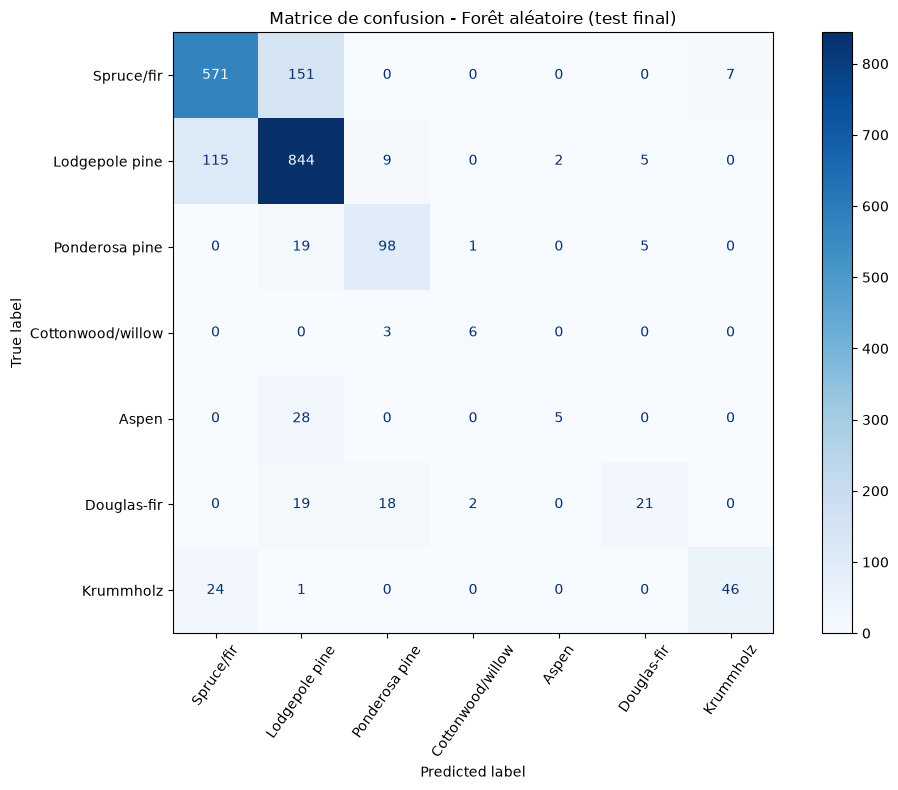

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

modele_final_name = tableau_comparaison.loc[0, "Modèle"]
modele_final = models[modele_final_name]
modele_final.fit(X_train, y_train)
prediction_finale = modele_final.predict(X_test)

print(f"Modèle évalué une seule fois sur le test : {modele_final_name}")
afficher_metriques(y_test, prediction_finale, class_names)

print("\nRapport de classification sur le test :")
print(
    classification_report(
        y_test,
        prediction_finale,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0,
    )
)

affichage_cm = ConfusionMatrixDisplay.from_predictions(
    y_test,
    prediction_finale,
    labels=np.arange(len(class_names)),
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=55,
    values_format="d",
)
affichage_cm.figure_.set_size_inches(11, 8)
affichage_cm.ax_.set_title(f"Matrice de confusion - {modele_final_name} (test final)")
plt.tight_layout()
plt.show()

### Interpréter les résultats du test

La **forêt aléatoire**, choisie parce qu'elle avait le meilleur mIoU moyen en validation croisée, obtient sur les 2 000 parcelles de test une OA de `79,5 %` et un mIoU de `50,5 %`. L'OA élevée est en partie portée par les classes fréquentes ; le mIoU donne le même poids aux sept espèces.

La forêt reconnaît bien Spruce/fir, Lodgepole pine et Ponderosa pine (IoU de `64–71 %`). L'Aspen reste difficile : son IoU est `14,3 %`, et 28 des 33 parcelles Aspen du test sont prédites Lodgepole pine. Il n'y a que 9 cas Cottonwood/willow dans le test ; son IoU de `50 %` est donc très incertain.

Ces chiffres viennent d'un échantillon stratifié de 10 000 parcelles et d'un seul split aléatoire. Ils servent à apprendre le protocole, pas à certifier une carte forestière réelle. Pour estimer la généralisation géographique, il faudrait réserver des zones spatiales entières au test.

## 9. Quelles variables la forêt utilise-t-elle ?

Une forêt aléatoire fournit une importance basée sur la diminution d'impureté : elle résume à quel point chaque variable a aidé les arbres à séparer les classes pendant l'entraînement.

Cette importance est descriptive, pas causale. Elle peut favoriser certaines variables continues et ne mesure pas à elle seule le gain obtenu en supprimant une caractéristique.

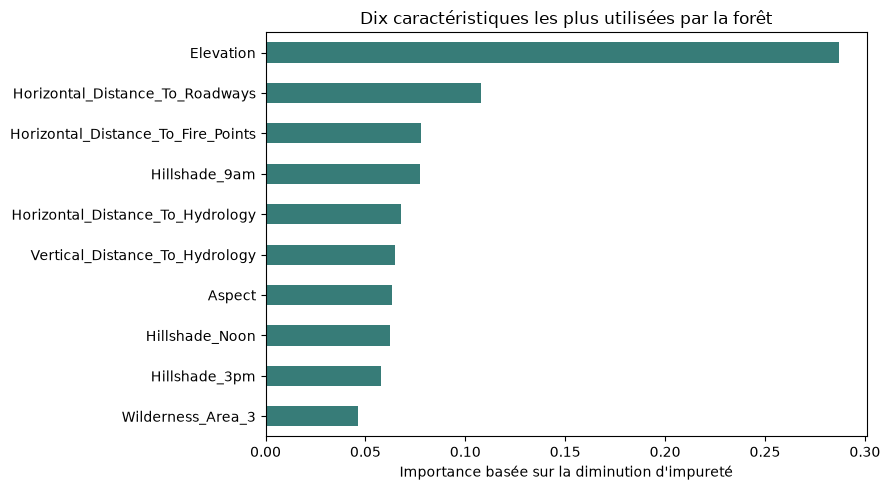

In [15]:
modele_foret_importance = models["Forêt aléatoire"]
modele_foret_importance.fit(X_train, y_train)

importances = pd.Series(
    modele_foret_importance.feature_importances_,
    index=feature_names,
).sort_values(ascending=True).tail(10)

fig, ax = plt.subplots(figsize=(9, 5))
importances.plot(kind="barh", ax=ax, color="#377c78")
ax.set_xlabel("Importance basée sur la diminution d'impureté")
ax.set_title("Dix caractéristiques les plus utilisées par la forêt")
fig.tight_layout()
plt.show()

L'altitude ressort nettement comme la variable la plus utilisée par cette forêt. Cette importance dépend du modèle et des données d'entraînement ; elle ne prouve pas que l'altitude cause le type de couverture, ni que les autres variables sont inutiles.

## Sources et limites

- Jeu de données : [UCI Covertype](https://archive.ics.uci.edu/dataset/31/covertype), téléchargé sans authentification par `sklearn.datasets.fetch_covtype`.
- Documentation du chargeur : [scikit-learn - fetch_covtype](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_covtype.html).

Le modèle présenté utilise un échantillon stratifié de 10 000 parcelles et 14 des 54 caractéristiques originales. La validation aléatoire est utile pour apprendre le protocole, mais les parcelles voisines peuvent se ressembler. Pour estimer une performance sur une autre région, il faudrait réserver des zones géographiques entières au test.